# Facial Expression Recognition — Hybrid Feature Descriptor + Jaya-LSSVM

**Replikasi jurnal**: Kar, N.B., Nayak, D.R., Babu, K.S., Zhang, Y.-D. (2021).
*A hybrid feature descriptor with Jaya optimised least squares SVM for facial expression recognition.*
IET Image Processing, 15(7), 1471–1483. DOI: [10.1049/ipr2.12118](https://doi.org/10.1049/ipr2.12118) (Open Access, CC-BY)

## Pipeline Lengkap Jurnal

```
Citra wajah (dataset CK+ / JAFFE)
        |
        v
[1] PREPROCESSING  ---- grayscale -> resize 128x128 -> histogram equalization   <== NOTEBOOK INI
        |
        v
[2] SWT (Haar, 1 level)  ---- stasioner wavelet transform -> 4 subband: LL, LH, HL, HH
        |
        v
[3] PHOG pada subband LL ---- Pyramid of Histogram of Oriented Gradients
        |
        v
[4] LDA ---- seleksi/reduksi dimensi fitur yang relevan
        |
        v
[5] JAYA-LSSVM ---- Least Squares SVM, parameter (gamma, sigma) dioptimasi algoritma Jaya
        |
        v
Klasifikasi 7 ekspresi ---- evaluasi: 5-fold stratified cross-validation
```

## Dataset yang Dipakai

| Dataset | Jumlah citra | Kelas | Struktur |
|---|---|---|---|
| **CK+** (Extended Cohn-Kanade) | 981 | anger, contempt, disgust, fear, happy, sadness, surprise | folder per kelas |
| **JAFFE** (Japanese Female Facial Expression) | 213 | anger, disgust, fear, happy, neutral, sadness, surprise | folder datar, kode ekspresi di nama file |

## Cakupan Notebook Ini
1. Loading kedua dataset + parsing label
2. **EDA** (distribusi kelas, ukuran citra, galeri sampel)
3. **Preprocessing sesuai jurnal** (grayscale, resize 128x128, histogram equalization)
4. Menyimpan hasil sebagai `.npz` siap pakai untuk tahap ekstraksi fitur
5. **Pratinjau tahap berikutnya**: dekomposisi SWT Haar level-1

> **Cara menjalankan**: pilih kernel **"Python 3.14 (LS-SVM TA)"** (atau venv `.venv` di folder ini), lalu *Run All*.

## 1. Import Library & Konfigurasi

Library yang digunakan:
- `numpy` — operasi array/matriks citra
- `cv2` (OpenCV) — membaca citra, resize, histogram equalization
- `matplotlib` — visualisasi
- `pandas` — tabel rekapitulasi
- `pywt` (PyWavelets) — pratinjau SWT di bagian akhir
- `re`, `pathlib` — parsing nama file & manajemen path

In [1]:
import re
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt

# ===== Konfigurasi path =====
DATASET_DIR = Path(r"D:\Semester5\pcvk\dataset")
CK_DIR      = DATASET_DIR / "ck+"
JAFFE_DIR   = DATASET_DIR / "jaffe"
OUTPUT_DIR  = Path(r"D:\Semester5\pcvk\tugas_akhir\data")   # folder penyimpanan hasil

# ===== Konstanta mengikuti jurnal =====
IMG_SIZE     = 128   # ukuran resize seragam (experimental setup jurnal)
RANDOM_STATE = 42    # agar hasil sampling visualisasi reprodusibel

# Verifikasi keberadaan dataset
for name, p in [("CK+", CK_DIR), ("JAFFE", JAFFE_DIR)]:
    status = "OK" if p.exists() else "TIDAK DITEMUKAN!"
    print(f"Dataset {name:6s}: {p}  [{status}]")

print(f"\nnumpy {np.__version__} | OpenCV {cv2.__version__} | PyWavelets {pywt.__version__}")

Dataset CK+   : D:\Semester5\pcvk\dataset\ck+  [OK]
Dataset JAFFE : D:\Semester5\pcvk\dataset\jaffe  [OK]

numpy 2.5.4 | OpenCV 5.0.0 | PyWavelets 1.8.0


## 2. Loading Dataset CK+ (Extended Cohn-Kanade)

Struktur folder CK+ sudah terorganisir **per kelas ekspresi** (7 folder). Nama file mengikuti pola:

```
S010_004_00000017.png
|    |    |
|    |    +-- nomor frame dalam sekuens
|    +------- nomor sekuens
+------------ subjek ke-10
```

Poin penting:
- Citra CK+ **sudah ter-crop dan ter-align ke wajah** (hasil anotasi landmark), sehingga tahap deteksi wajah tidak diperlukan lagi.
- Citra langsung dimuat dalam mode **grayscale** (`cv2.IMREAD_GRAYSCALE`) — ini sudah merupakan langkah pertama preprocessing jurnal.
- Informasi **subjek** ikut disimpan, berguna untuk skema evaluasi *subject-independent* di tahap klasifikasi.

In [2]:
def parse_ck_filename(fname: str):
    """S010_004_00000017 -> (subjek='S010', sekuens='004')"""
    m = re.match(r"(S\d+)_(\d+)_(\d+)", fname)
    return (m.group(1), m.group(2)) if m else ("unknown", "unknown")


def load_ckplus(data_dir: Path):
    """Memuat seluruh citra CK+ dari folder per kelas.

    Returns:
        images      : list array uint8 (H x W) grayscale
        labels      : array int indeks kelas
        subjects    : array str kode subjek
        class_names : daftar nama kelas (urut alfabet -> indeks label konsisten)
    """
    images, labels, subjects = [], [], []
    class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())

    for cls_idx, cls in enumerate(class_names):
        files = sorted((data_dir / cls).glob("*.png"))
        for f in files:
            img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
            if img is None:
                print(f"  [peringatan] gagal membaca: {f.name}")
                continue
            images.append(img)
            labels.append(cls_idx)
            subjects.append(parse_ck_filename(f.stem)[0])

    return images, np.array(labels), np.array(subjects), class_names


ck_images, ck_labels, ck_subjects, ck_classes = load_ckplus(CK_DIR)

print(f"Total citra CK+ termuat : {len(ck_images)}")
print(f"Kelas ({len(ck_classes)})            : {ck_classes}")
print(f"Jumlah subjek unik      : {len(set(ck_subjects))}")
unique_sizes = {img.shape for img in ck_images}
print(f"Ukuran citra unik       : {len(unique_sizes)} macam -> {sorted(unique_sizes)}")

Total citra CK+ termuat : 981
Kelas (7)            : ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Jumlah subjek unik      : 118
Ukuran citra unik       : 1 macam -> [(48, 48)]


## 3. Loading Dataset JAFFE

JAFFE berisi 213 citra ekspresi wajah 10 subjek wanita Jepang dalam **satu folder datar**. Label kelas diekstrak dari nama file:

```
0000_KA.AN1.39.png
|    |  |
|    |  +-- kode ekspresi: AN = anger
|    +----- kode subjek: KA
+---------- nomor urut
```

Pemetaan kode ekspresi JAFFE:

| Kode | Ekspresi | | Kode | Ekspresi |
|---|---|---|---|---|
| AN | anger | | HA | happy |
| DI | disgust | | NE | neutral |
| FE | fear | | SA | sadness |
| | | | SU | surprise |

> **Catatan**: JAFFE memiliki kelas `neutral` sedangkan CK+ tidak (CK+ punya `contempt` sebagai gantinya). Kedua dataset diproses **secara independen** dengan pemetaan labelnya masing-masing — sama seperti jurnal yang mengevaluasi tiap dataset terpisah. File non-citra (`images.npy`, `infos.json`) otomatis dilewati karena hanya pola `*.png` yang dibaca.

In [3]:
JAFFE_CODE_MAP = {
    "AN": "anger",
    "DI": "disgust",
    "FE": "fear",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sadness",
    "SU": "surprise",
}


def parse_jaffe_filename(fname: str):
    """0000_KA.AN1.39.png -> (subjek='KA', kode_ekspresi='AN')"""
    m = re.match(r"\d+_([A-Z]{2})\.([A-Z]{2})\d", fname)
    return (m.group(1), m.group(2)) if m else (None, None)


def load_jaffe(data_dir: Path):
    """Memuat seluruh citra JAFFE dan melabeli dari kode pada nama file."""
    images, labels, subjects = [], [], []
    jaffe_classes = sorted(JAFFE_CODE_MAP.values())  # urutan label konsisten

    for f in sorted(data_dir.glob("*.png")):
        subj, kode = parse_jaffe_filename(f.name)
        if kode is None or kode not in JAFFE_CODE_MAP:
            print(f"  [peringatan] nama file tidak dikenali, dilewati: {f.name}")
            continue
        img = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        if img is None:
            print(f"  [peringatan] gagal membaca: {f.name}")
            continue
        images.append(img)
        labels.append(jaffe_classes.index(JAFFE_CODE_MAP[kode]))
        subjects.append(subj)

    return images, np.array(labels), np.array(subjects), jaffe_classes


jaffe_images, jaffe_labels, jaffe_subjects, jaffe_classes = load_jaffe(JAFFE_DIR)

print(f"Total citra JAFFE termuat: {len(jaffe_images)}")
print(f"Kelas ({len(jaffe_classes)})           : {jaffe_classes}")
print(f"Jumlah subjek unik       : {len(set(jaffe_subjects))}")

Total citra JAFFE termuat: 213
Kelas (7)           : ['anger', 'disgust', 'fear', 'happy', 'neutral', 'sadness', 'surprise']
Jumlah subjek unik       : 10


## 4. Exploratory Data Analysis (EDA)

Sebelum preprocessing, kita periksa dulu tiga hal:
1. **Distribusi kelas** — apakah ada ketidakseimbangan (imbalance) yang perlu diantisipasi saat evaluasi?
2. **Ukuran citra asli** — sudah seragamkan? sesuai 128x128 (setup jurnal)?
3. **Sampel visual** — memastikan citra termuat benar dan labelnya sesuai.

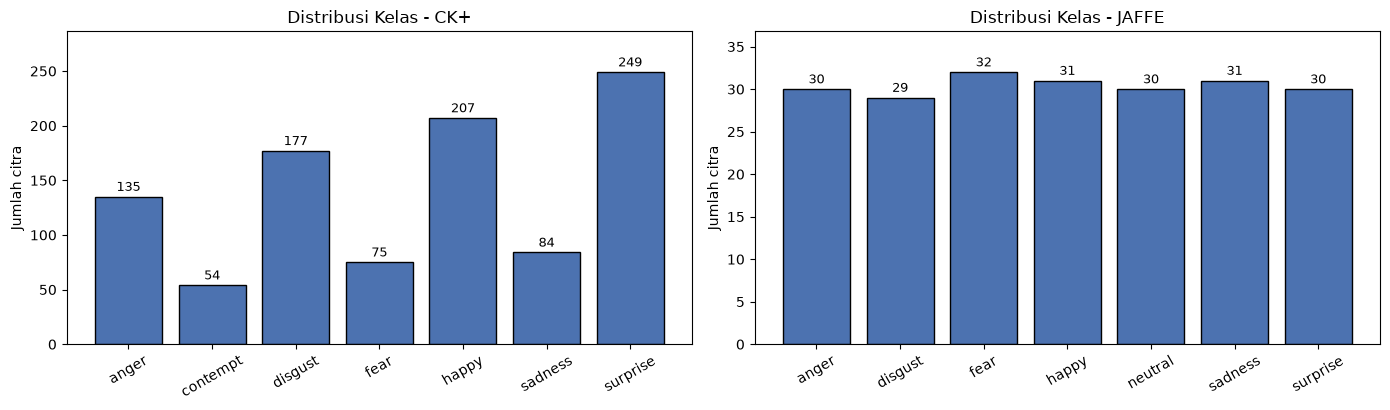

== CK+ ==
        anger  contempt  disgust  fear  happy  sadness  surprise
jumlah    135        54      177    75    207       84       249

== JAFFE ==
        anger  disgust  fear  happy  neutral  sadness  surprise
jumlah     30       29    32     31       30       31        30


In [4]:
def class_distribution(labels, class_names):
    """Tabel jumlah citra per kelas."""
    counts = [int((labels == i).sum()) for i in range(len(class_names))]
    return pd.DataFrame({"jumlah": counts}, index=class_names)


ck_df    = class_distribution(ck_labels, ck_classes)
jaffe_df = class_distribution(jaffe_labels, jaffe_classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, df, title in zip(axes, [ck_df, jaffe_df], ["CK+", "JAFFE"]):
    bars = ax.bar(df.index, df["jumlah"], color="#4C72B0", edgecolor="black")
    ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_title(f"Distribusi Kelas - {title}")
    ax.set_ylabel("Jumlah citra")
    ax.set_ylim(0, df["jumlah"].max() * 1.15)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print("== CK+ ==\n", ck_df.T, sep="")
print("\n== JAFFE ==\n", jaffe_df.T, sep="")

In [5]:
def size_stats(images, name):
    """Statistik ukuran (tinggi x lebar) citra asli."""
    shapes = np.array([img.shape for img in images])  # kolom: (tinggi, lebar)
    print(f"--- {name} ---")
    print(f"  tinggi : min={shapes[:, 0].min():4d}  maks={shapes[:, 0].max():4d}")
    print(f"  lebar  : min={shapes[:, 1].min():4d}  maks={shapes[:, 1].max():4d}")
    print(f"  jumlah kombinasi ukuran unik: {len({tuple(s) for s in shapes})}")
    return shapes


ck_shapes    = size_stats(ck_images, "CK+")
print()
jaffe_shapes = size_stats(jaffe_images, "JAFFE")

# Kesimpulan dinamis berdasarkan kondisi nyata dataset
print("\n>> Kesimpulan EDA ukuran:")
for name, shapes in [("CK+", ck_shapes), ("JAFFE", jaffe_shapes)]:
    uniq = {tuple(s) for s in shapes}
    if len(uniq) == 1:
        h, w = uniq.pop()
        if (h, w) == (IMG_SIZE, IMG_SIZE):
            ket = f"sudah sesuai setup jurnal {IMG_SIZE}x{IMG_SIZE} (resize = no-op)"
        else:
            arah = "di-upscale" if max(h, w) < IMG_SIZE else "di-downscale"
            ket = f"perlu {arah} ke {IMG_SIZE}x{IMG_SIZE}"
        print(f"   {name:6s}: seragam {h}x{w} -> {ket}")
    else:
        print(f"   {name:6s}: BERAGAM ({len(uniq)} ukuran berbeda) "
              f"-> perlu resize seragam ke {IMG_SIZE}x{IMG_SIZE}")
print("""
   Resize ke 128x128 (experimental setup jurnal) tetap WAJIB dilakukan agar:
   (a) kedua dataset berdimensi sama, (b) vektor fitur PHOG konsisten panjangnya.""")

--- CK+ ---
  tinggi : min=  48  maks=  48
  lebar  : min=  48  maks=  48
  jumlah kombinasi ukuran unik: 1

--- JAFFE ---
  tinggi : min= 128  maks= 128
  lebar  : min= 128  maks= 128
  jumlah kombinasi ukuran unik: 1

>> Kesimpulan EDA ukuran:
   CK+   : seragam 48x48 -> perlu di-upscale ke 128x128
   JAFFE : seragam 128x128 -> sudah sesuai setup jurnal 128x128 (resize = no-op)

   Resize ke 128x128 (experimental setup jurnal) tetap WAJIB dilakukan agar:
   (a) kedua dataset berdimensi sama, (b) vektor fitur PHOG konsisten panjangnya.


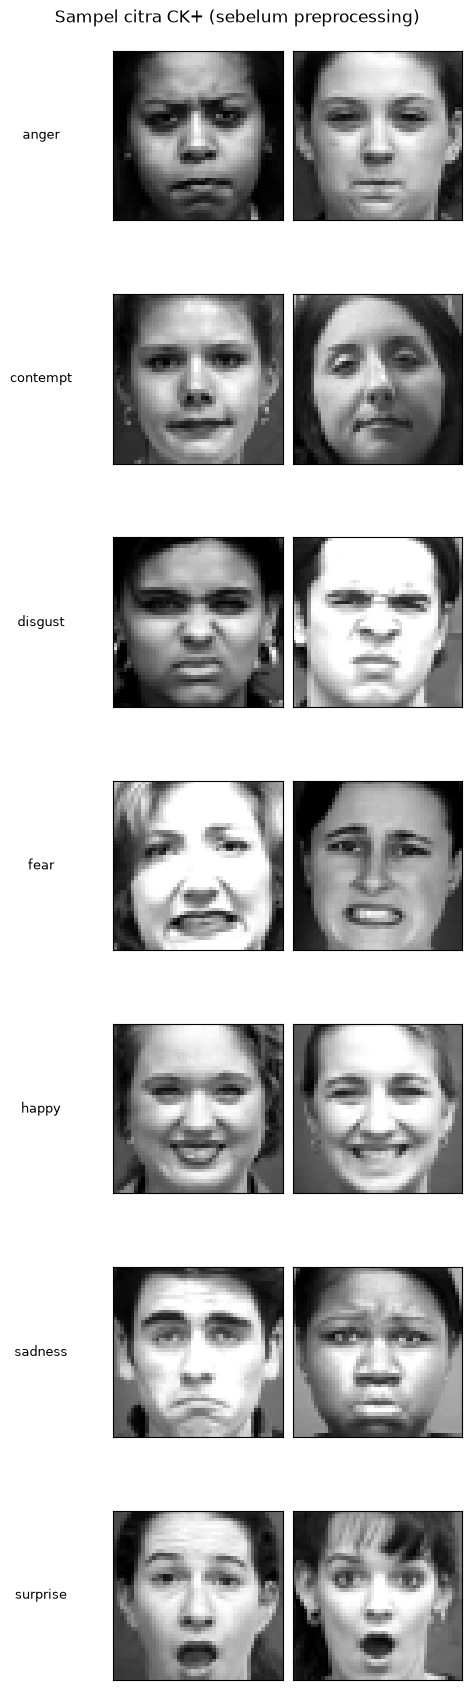

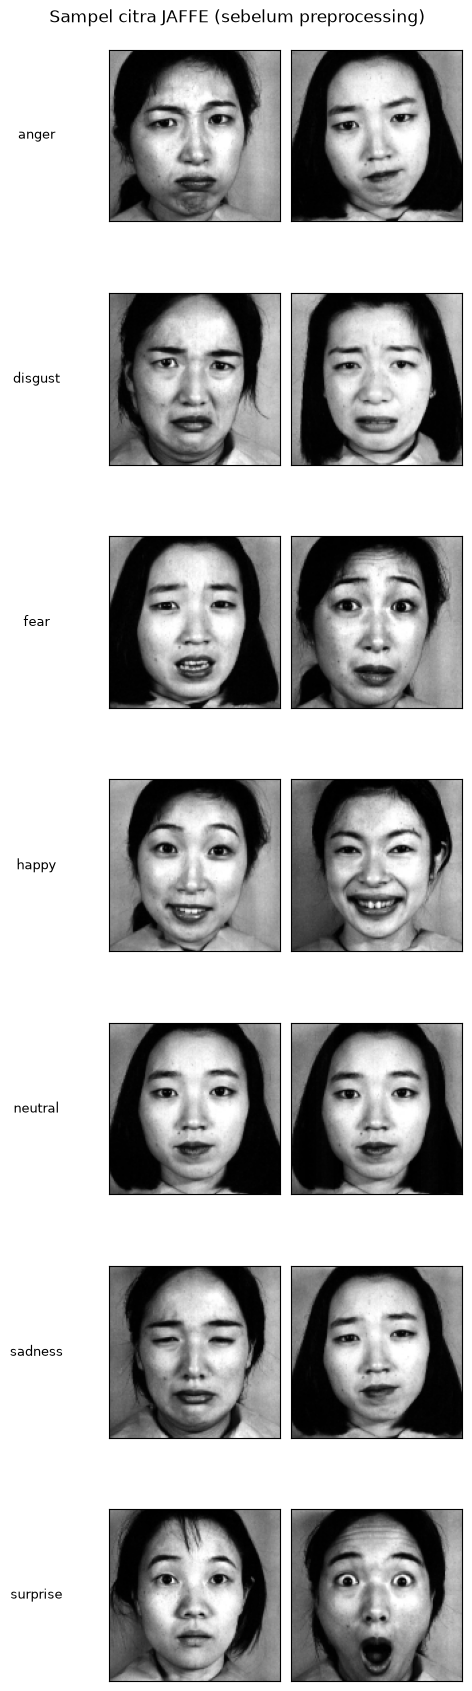

In [6]:
def show_gallery(images, labels, class_names, title, per_class=2):
    """Menampilkan beberapa sampel citra untuk setiap kelas."""
    n_cls = len(class_names)
    fig, axes = plt.subplots(n_cls, per_class, figsize=(2.4 * per_class, 2.5 * n_cls))
    rng = np.random.default_rng(RANDOM_STATE)
    for i, cls in enumerate(class_names):
        idx = np.where(labels == i)[0]
        picks = rng.choice(idx, size=min(per_class, len(idx)), replace=False)
        for j, p in enumerate(picks):
            ax = axes[i, j] if per_class > 1 else axes[i]
            ax.imshow(images[p], cmap="gray")
            if j == 0:
                ax.set_ylabel(cls, rotation=0, labelpad=52, fontsize=9,
                              va="center")
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()


show_gallery(ck_images, ck_labels, ck_classes,
             "Sampel citra CK+ (sebelum preprocessing)")
show_gallery(jaffe_images, jaffe_labels, jaffe_classes,
             "Sampel citra JAFFE (sebelum preprocessing)")

## 5. Preprocessing Sesuai Jurnal

Tahap preprocessing pada jurnal terdiri dari tiga langkah berurutan:

### 5.1 Konversi Grayscale
Informasi ekspresi wajah terletak pada **geometri dan intensitas** (kerutan dahi, alis, sudut mulut, kelopak mata) — bukan pada warna kulit. Deskriptor jurnal (SWT + PHOG) bekerja pada citra **satu kanal**, sehingga citra dikonversi ke grayscale menggunakan pembobotan luminansi:

$$Y = 0.299R + 0.587G + 0.114B$$

Pada implementasi ini, konversi sudah dilakukan saat loading (`cv2.IMREAD_GRAYSCALE`); fungsi `to_grayscale()` di bawah disediakan agar pipeline tetap lengkap untuk citra berwarna.

### 5.2 Resize ke 128 x 128
**PHOG menghasilkan vektor fitur dengan panjang tetap** — syaratnya semua citra berdimensi sama, dan setup eksperimen jurnal memakai **128 x 128 piksel**. Hasil EDA pada salinan dataset kita: CK+ berukuran 48x48 (perlu *upscaling*) dan JAFFE sudah tepat 128x128. Karena itu interpolasi dipilih **adaptif**:

- **Downscaling** (memperkecil) -> `cv2.INTER_AREA`: merata-ratakan area piksel tetangga sehingga hasil halus dan bebas efek *aliasing*.
- **Upscaling** (memperbesar, kasus CK+ 48 -> 128) -> `cv2.INTER_CUBIC`: interpolasi bikubik yang menghasilkan transisi lebih wajar dibanding *nearest/bilinear*.

### 5.3 Histogram Equalization
Perbedaan kondisi pencahayaan antar citra menggeser distribusi intensitas — ekspresi sama bisa menghasilkan nilai fitur berbeda. Histogram equalization **merentangkan** distribusi intensitas agar memenuhi seluruh rentang [0, 255] dengan transformasi CDF:

$$s_k = \mathrm{round}\left((L-1) \sum_{j=0}^{k} p_j\right), \quad L = 256$$

dengan $p_j$ = frekuensi relatif intensitas $j$. Hasilnya: kontras dinormalisasi sehingga fitur lebih **robust terhadap variasi iluminasi** — sejalan dengan klaim jurnal bahwa deskriptor hybrid-nya tahan iluminasi dan noise.

### Kenapa tidak ada deteksi/crop wajah?
Kedua dataset **sudah ter-crop ke wajah** (CK+ ter-align dengan landmark; JAFFE sudah pre-cropped), sehingga normalisasi langsung dimulai dari tiga langkah di atas.

In [7]:
def to_grayscale(img):
    """Langkah 1: pastikan citra satu kanal (grayscale)."""
    if img.ndim == 3:
        return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img


def resize_uniform(img, size=IMG_SIZE):
    """Langkah 2: resize ke (size x size) dengan interpolasi adaptif.
    - Downscaling (citra lebih besar dari target) -> INTER_AREA
      (rata-rata area piksel tetangga, hasil halus tanpa aliasing).
    - Upscaling (citra lebih kecil, mis. CK+ 48 -> 128) -> INTER_CUBIC
      (interpolasi bikubik, detail lebih wajar daripada nearest/bilinear).
    """
    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if (h > size or w > size) else cv2.INTER_CUBIC
    return cv2.resize(img, (size, size), interpolation=interp)


def equalize_histogram(img):
    """Langkah 3: histogram equalization untuk normalisasi iluminasi/kontras."""
    return cv2.equalizeHist(img)


def preprocess_image(img, size=IMG_SIZE):
    """Pipeline preprocessing lengkap sesuai jurnal Kar et al. (2021).

    citra asli -> grayscale -> resize 128x128 -> histogram equalization
    """
    img = to_grayscale(img)
    img = resize_uniform(img, size)
    img = equalize_histogram(img)
    return img


# Uji cepat pada satu citra
contoh = preprocess_image(ck_images[0])
print(f"Bentuk sebelum : {ck_images[0].shape}")
print(f"Bentuk sesudah : {contoh.shape}, dtype={contoh.dtype}, "
      f"rentang=[{contoh.min()}, {contoh.max()}]")

Bentuk sebelum : (48, 48)
Bentuk sesudah : (128, 128), dtype=uint8, rentang=[0, 255]


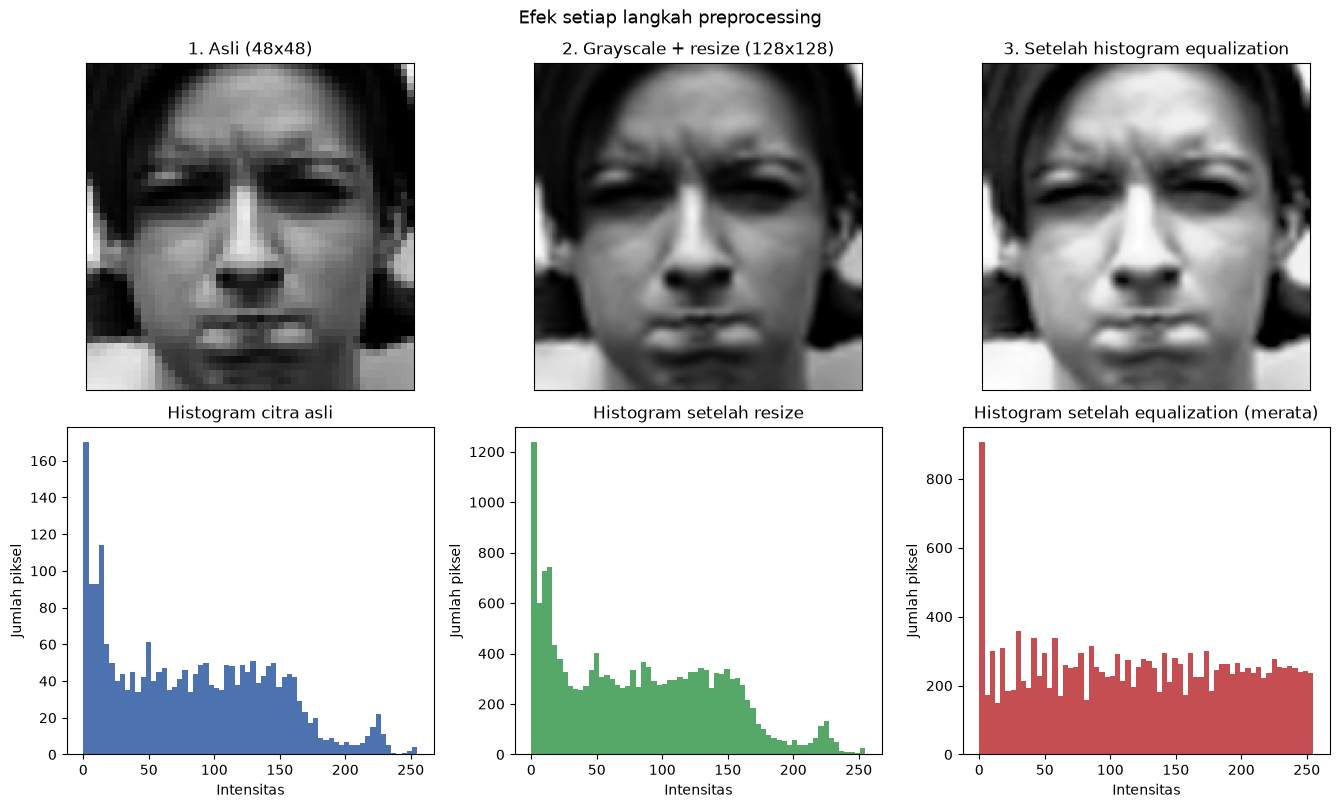


>> Perhatikan histogram baris bawah: setelah equalization, distribusi intensitas
   menyebar merata ke seluruh rentang 0-255. Inilah normalisasi iluminasi yang
   membuat fitur citra lebih konsisten antar sampel.


In [8]:
# Visualisasi efek tiap langkah pada satu citra sampel
sample     = ck_images[0]
step12     = resize_uniform(to_grayscale(sample))          # grayscale + resize
step_final = equalize_histogram(step12)                    # + equalization

fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.2))

# Baris atas: citra
axes[0, 0].imshow(sample, cmap="gray")
axes[0, 0].set_title(f"1. Asli ({sample.shape[1]}x{sample.shape[0]})")
axes[0, 1].imshow(step12, cmap="gray")
axes[0, 1].set_title(f"2. Grayscale + resize ({IMG_SIZE}x{IMG_SIZE})")
axes[0, 2].imshow(step_final, cmap="gray")
axes[0, 2].set_title("3. Setelah histogram equalization")
for ax in axes[0]:
    ax.set_xticks([]); ax.set_yticks([])

# Baris bawah: histogram intensitasnya
axes[1, 0].hist(sample.ravel(), bins=64, range=(0, 255), color="#4C72B0")
axes[1, 0].set_title("Histogram citra asli")
axes[1, 1].hist(step12.ravel(), bins=64, range=(0, 255), color="#55A868")
axes[1, 1].set_title("Histogram setelah resize")
axes[1, 2].hist(step_final.ravel(), bins=64, range=(0, 255), color="#C44E52")
axes[1, 2].set_title("Histogram setelah equalization (merata)")
for ax in axes[1]:
    ax.set_xlabel("Intensitas"); ax.set_ylabel("Jumlah piksel")

plt.suptitle("Efek setiap langkah preprocessing", fontsize=13)
plt.tight_layout()
plt.show()

print("""
>> Perhatikan histogram baris bawah: setelah equalization, distribusi intensitas
   menyebar merata ke seluruh rentang 0-255. Inilah normalisasi iluminasi yang
   membuat fitur citra lebih konsisten antar sampel.""")

## 6. Terapkan Preprocessing ke Seluruh Dataset

Semua citra CK+ (981) dan JAFFE (213) diproses menjadi array numpy seragam:

- `X` berbentuk `(N, 128, 128)` dengan `dtype=uint8` — hemat memori (~16 MB untuk CK+; konversi ke `float64` baru dilakukan saat ekstraksi fitur SWT/PHOG).
- `y` berisi indeks label kelas.
- `subjects` dan `class_names` disertakan untuk kebutuhan evaluasi nanti.

In [9]:
def build_dataset(images, labels, subjects, class_names):
    """Menerapkan preprocess_image ke seluruh citra dan menyusunnya jadi array."""
    X = np.array([preprocess_image(img) for img in images], dtype=np.uint8)
    return X, labels.astype(np.int8), subjects, class_names


X_ck,    y_ck,    subj_ck,    classes_ck    = build_dataset(
    ck_images, ck_labels, ck_subjects, ck_classes)
X_jaffe, y_jaffe, subj_jaffe, classes_jaffe = build_dataset(
    jaffe_images, jaffe_labels, jaffe_subjects, jaffe_classes)

# ===== Verifikasi hasil =====
for name, X, y, classes in [("CK+", X_ck, y_ck, classes_ck),
                            ("JAFFE", X_jaffe, y_jaffe, classes_jaffe)]:
    print(f"--- {name} ---")
    print(f"  X.shape       : {X.shape}   (N, tinggi, lebar)")
    print(f"  X.dtype       : {X.dtype}")
    print(f"  rentang piksel: [{X.min()}, {X.max()}]")
    print(f"  y.shape       : {y.shape}, label unik: {np.unique(y).tolist()}")
    print(f"  kelas         : {classes}")
    assert X.shape[1:] == (IMG_SIZE, IMG_SIZE), "Ukuran tidak seragam!"
    assert len(np.unique(y)) == len(classes), "Jumlah label != jumlah kelas!"
print("\nSemua pemeriksaan lolos ✔")

--- CK+ ---
  X.shape       : (981, 128, 128)   (N, tinggi, lebar)
  X.dtype       : uint8
  rentang piksel: [0, 255]
  y.shape       : (981,), label unik: [0, 1, 2, 3, 4, 5, 6]
  kelas         : ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
--- JAFFE ---
  X.shape       : (213, 128, 128)   (N, tinggi, lebar)
  X.dtype       : uint8
  rentang piksel: [0, 255]
  y.shape       : (213,), label unik: [0, 1, 2, 3, 4, 5, 6]
  kelas         : ['anger', 'disgust', 'fear', 'happy', 'neutral', 'sadness', 'surprise']

Semua pemeriksaan lolos ✔


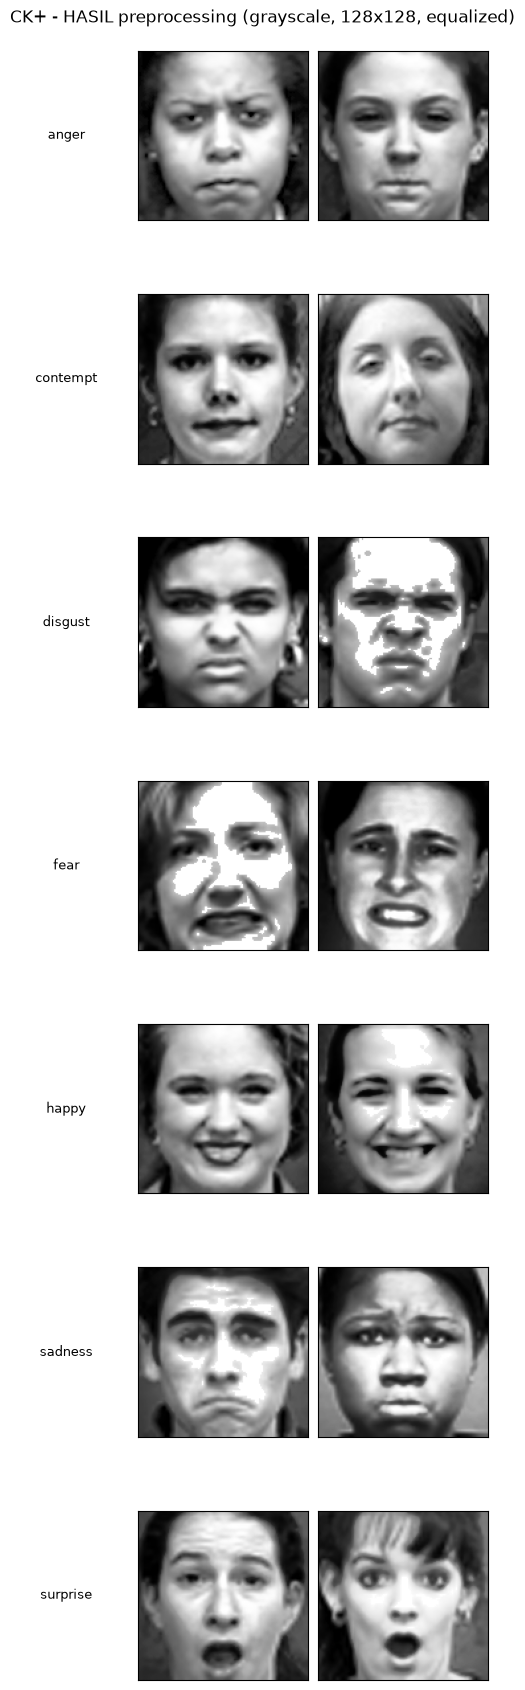

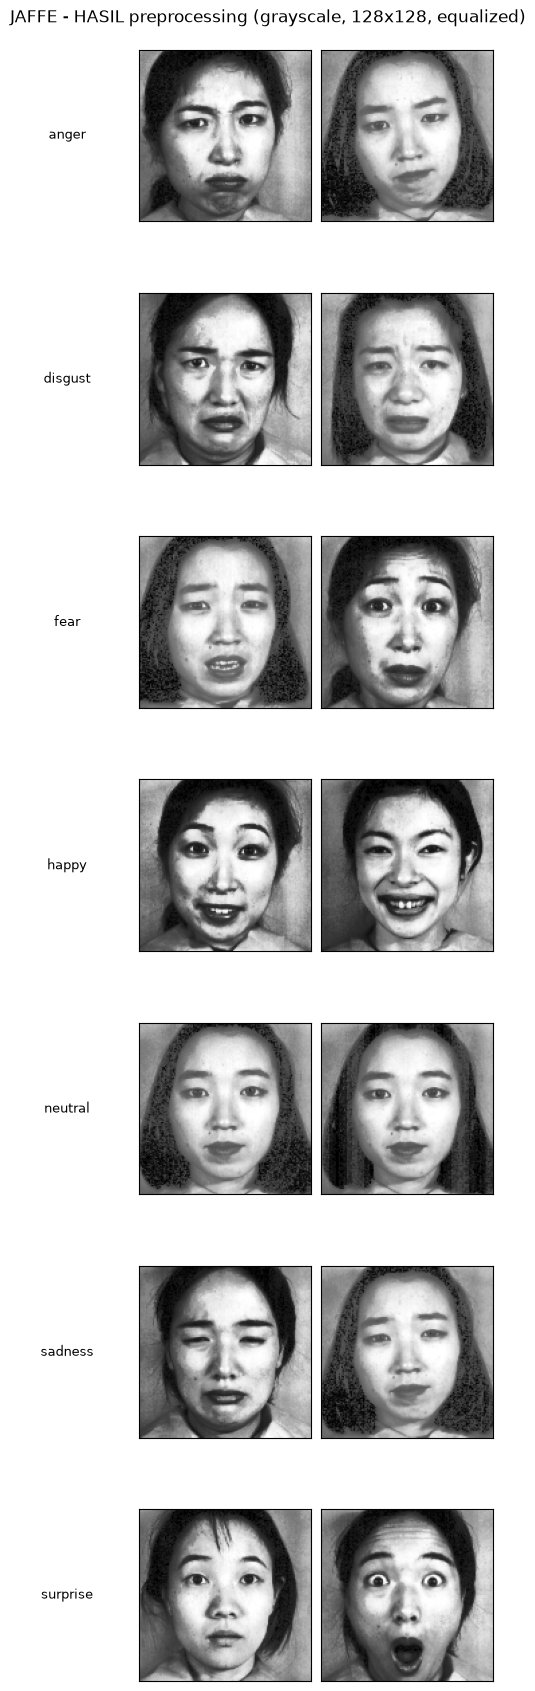

In [10]:
# Galeri hasil akhir preprocessing (2 sampel per kelas)
show_gallery(X_ck, y_ck, classes_ck,
             "CK+ - HASIL preprocessing (grayscale, 128x128, equalized)")
show_gallery(X_jaffe, y_jaffe, classes_jaffe,
             "JAFFE - HASIL preprocessing (grayscale, 128x128, equalized)")

## 7. Menyimpan Hasil Preprocessing (`.npz`)

Hasil disimpan ke `D:\Semester5\pcvk\tugas_akhir\data\`:

| File | Isi |
|---|---|
| `ck_preprocessed.npz` | `X`, `y`, `subjects`, `class_names` untuk CK+ |
| `jaffe_preprocessed.npz` | `X`, `y`, `subjects`, `class_names` untuk JAFFE |

**Kenapa tidak sekalian dibagi train/test di sini?**
Jurnal mengevaluasi dengan **5-fold stratified cross-validation** — pembagian fold dilakukan di tahap eksperimen menggunakan `sklearn.model_selection.StratifiedKFold` (setiap kelas terwakili proporsional di tiap fold, dan diulang 5 kali sehingga seluruh data pernah menjadi data uji). Karena itu, hasil preprocessing disimpan **utuh** tanpa split, agar tahap berikutnya fleksibel.

In [11]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(OUTPUT_DIR / "ck_preprocessed.npz",
                    X=X_ck, y=y_ck, subjects=subj_ck,
                    class_names=np.array(classes_ck))
np.savez_compressed(OUTPUT_DIR / "jaffe_preprocessed.npz",
                    X=X_jaffe, y=y_jaffe, subjects=subj_jaffe,
                    class_names=np.array(classes_jaffe))

print("File tersimpan:")
for f in sorted(OUTPUT_DIR.glob("*.npz")):
    print(f"  {f.name:28s} {f.stat().st_size / 1e6:8.2f} MB")

# Contoh cara memuat kembali di notebook tahap berikutnya:
#   data = np.load(r"D:\Semester5\pcvk\tugas_akhir\data\ck_preprocessed.npz")
#   X, y = data["X"], data["y"]

File tersimpan:
  ck_preprocessed.npz             12.67 MB
  jaffe_preprocessed.npz           3.11 MB


## 8. Pratinjau Tahap Berikutnya — SWT Haar Level-1

Jurnal menerapkan **Stationary Wavelet Transform (SWT)**, bukan DWT biasa:

| | DWT (biasa) | SWT (dipakai jurnal) |
|---|---|---|
| Downsampling | ya (ukuran subband mengecil 2x tiap level) | **tidak** (semua subband tetap 128x128) |
| Shift-invariance | tidak (fitur berubah jika citra bergeser beberapa piksel) | **ya** |
| Komputasi | lebih ringan | lebih berat, tapi lebih stabil untuk fitur |

Dekomposisi Haar level-1 menghasilkan **4 subband**:
- **LL** — komponen frekuensi rendah (aproksimasi struktur utama wajah) -> **di sinilah PHOG dihitung**
- **LH** — detail arah horizontal (mis. tepi mendatar: kelopak mata, garis bibir)
- **HL** — detail arah vertikal (mis. tepi tegak: sisi hidung)
- **HH** — detail diagonal (tekstur/sudut)

Sel di bawah mendemokan dekomposisi tersebut pada satu citra hasil preprocessing — jembatan ke notebook tahap ekstraksi fitur.

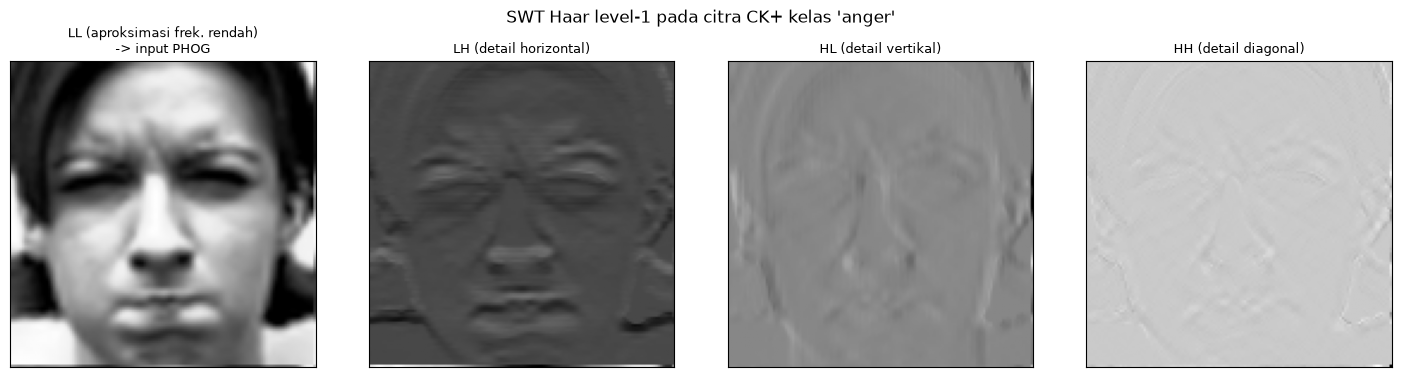

Bentuk citra input     : (128, 128)
Bentuk SEMUA subband   : (128, 128)  <- tidak ada downsampling (shift-invariant)

>> TAHAP BERIKUTNYA: hitung PHOG pada subband LL -> reduksi LDA -> klasifikasi Jaya-LSSVM.


In [12]:
img = X_ck[0].astype(np.float64)   # SWT memerlukan input float

# SWT Haar level-1. trim_approx=True -> format [LL, (LH, HL, HH)]
coeffs = pywt.swt2(img, wavelet="haar", level=1, trim_approx=True)
LL = coeffs[0]
LH, HL, HH = coeffs[1]   # konvensi pywt: (cH horizontal, cV vertikal, cD diagonal)

fig, axes = plt.subplots(1, 4, figsize=(14.5, 3.8))
for ax, sub, t in zip(axes, [LL, LH, HL, HH],
                      ["LL (aproksimasi frek. rendah)\n-> input PHOG",
                       "LH (detail horizontal)",
                       "HL (detail vertikal)",
                       "HH (detail diagonal)"]):
    ax.imshow(sub, cmap="gray")
    ax.set_title(t, fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"SWT Haar level-1 pada citra CK+ kelas '{classes_ck[y_ck[0]]}'",
             fontsize=12)
plt.tight_layout()
plt.show()

print(f"Bentuk citra input     : {img.shape}")
print(f"Bentuk SEMUA subband   : {LL.shape}  <- tidak ada downsampling (shift-invariant)")
print("\n>> TAHAP BERIKUTNYA: hitung PHOG pada subband LL -> reduksi LDA -> klasifikasi Jaya-LSSVM.")

## Ringkasan

Notebook ini telah menyelesaikan **tahap preprocessing** replikasi jurnal Kar et al. (2021):

1. **Loading** 981 citra CK+ (7 kelas, dari folder) dan 213 citra JAFFE (7 kelas, parsing kode nama file) — semuanya dalam grayscale.
2. **EDA**: distribusi kelas per dataset, variasi ukuran citra asli, dan galeri sampel per kelas.
3. **Preprocessing sesuai jurnal**: grayscale -> resize seragam **128x128** (interpolasi adaptif: `INTER_CUBIC` untuk upscale CK+ 48x48, `INTER_AREA` untuk downscale) -> **histogram equalization** (normalisasi iluminasi/kontras).
4. **Penyimpanan** hasil sebagai `data/ck_preprocessed.npz` dan `data/jaffe_preprocessed.npz` (berisi `X`, `y`, `subjects`, `class_names`), siap dipakai tahap ekstraksi fitur dengan skema evaluasi **5-fold stratified CV**.
5. **Pratinjau SWT Haar** level-1 (LL/LH/HL/HH) sebagai jembatan ke tahap berikutnya.

### Langkah selanjutnya (notebook terpisah)
- [ ] Ekstraksi **PHOG** dari subband **LL** hasil SWT Haar
- [ ] Reduksi fitur dengan **LDA**
- [ ] Klasifikasi **LSSVM** dengan tuning parameter (gamma, sigma) via **algoritma Jaya**
- [ ] Evaluasi **5-fold stratified cross-validation** pada CK+ dan JAFFE

### Referensi
Kar, N.B., Nayak, D.R., Babu, K.S., & Zhang, Y.-D. (2021). A hybrid feature descriptor with Jaya optimised least squares SVM for facial expression recognition. *IET Image Processing*, 15(7), 1471-1483. https://doi.org/10.1049/ipr2.12118